<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Hysteresis_Loop_Ni_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

In [ ]:
!uv pip install mumaxplus matplotlib numpy

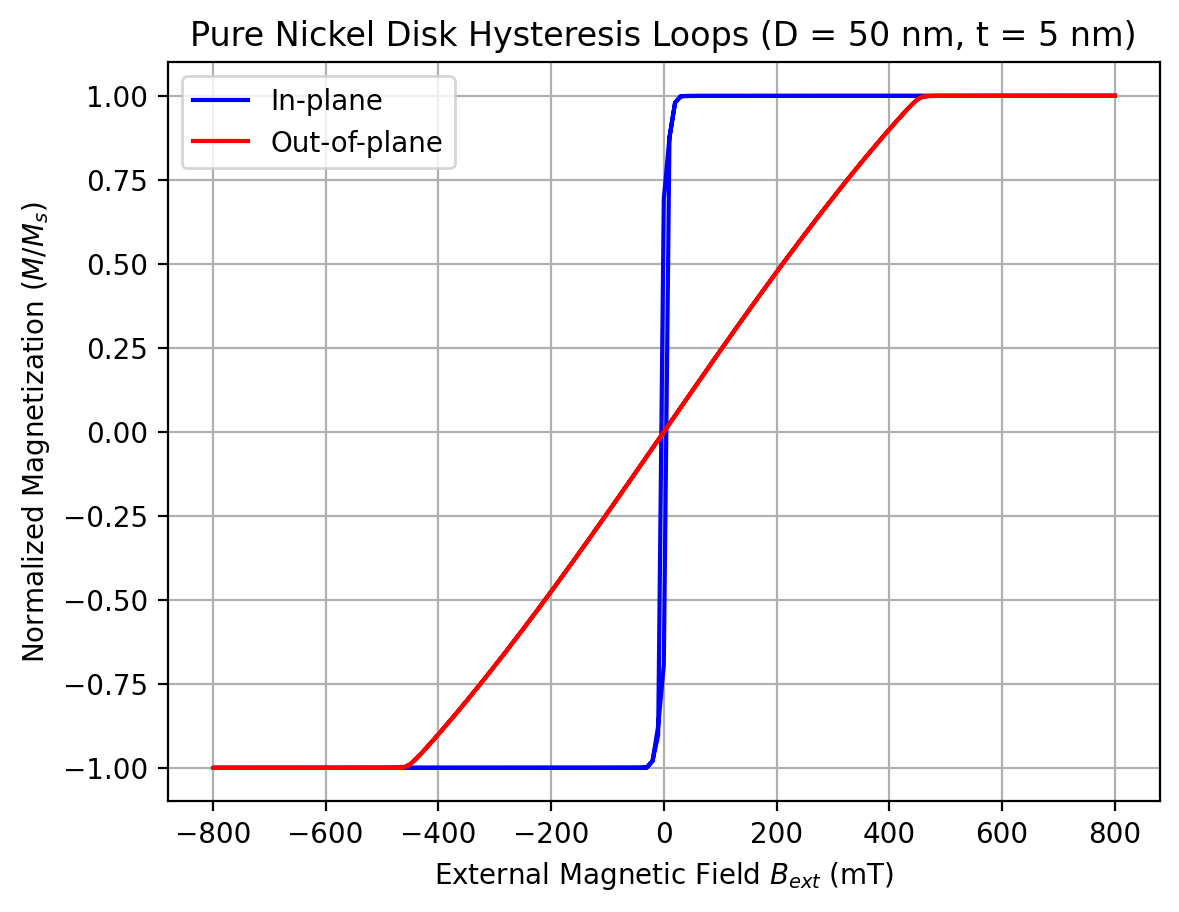

In [3]:
"""This script computes in-plane and out-of-plane pure nickel hysteresis loops.

The simulation models a 50 nm diameter, 5 nm thick circular pure nickel disk
discretized into 2.5 nm cubic cells using native mumaxplus syntax.
"""

import matplotlib.pyplot as plt
from mumaxplus import Ferromagnet
from mumaxplus import Grid
from mumaxplus import World
import numpy as np

plt.rcParams['figure.dpi'] = 200

world = World(cellsize=(2.5e-9, 2.5e-9, 2.5e-9))
grid = Grid((20, 20, 2))
z_idx, y_idx, x_idx = np.indices((2, 20, 20))
r_sq = ((x_idx - 9.5) * 2.5e-9) ** 2 + ((y_idx - 9.5) * 2.5e-9) ** 2
disk = r_sq <= (25e-9) ** 2

magnet = Ferromagnet(world, grid, geometry=disk)
magnet.msat = 4.9e5
magnet.aex = 9.0e-12
magnet.kc1 = -4.5e3
magnet.anisC1 = (1, 0, 0)
magnet.anisC2 = (0, 1, 0)
magnet.alpha = 0.045

b_max = 0.8
b_step = 0.01
b_array = np.concatenate((
    np.arange(b_max, -b_max - b_step * 0.5, -b_step),
    np.arange(-b_max + b_step, b_max + b_step * 0.5, b_step),
))

magnet.magnetization = (1.0, 0.05, 0.05)
world.bias_magnetic_field = (b_max, 5e-4, 5e-4)
magnet.relax()

mx_ip = []
for b_ext in b_array:
    world.bias_magnetic_field = (b_ext, 5e-4, 5e-4)
    magnet.minimize()
    mx_ip.append(magnet.magnetization.average()[0])

magnet.magnetization = (0.05, 0.05, 1.0)
world.bias_magnetic_field = (5e-4, 5e-4, b_max)
magnet.relax()

mz_oop = []
for b_ext in b_array:
    world.bias_magnetic_field = (5e-4, 5e-4, b_ext)
    magnet.minimize()
    mz_oop.append(magnet.magnetization.average()[2])

b_mt = b_array * 1e3
plt.plot(b_mt, mx_ip, color='blue', linewidth=1.5, label='In-plane')
plt.plot(b_mt, mz_oop, color='red', linewidth=1.5, label='Out-of-plane')
plt.xlabel('External Magnetic Field $B_{ext}$ (mT)')
plt.ylabel('Normalized Magnetization ($M/M_s$)')
plt.title('Pure Nickel Disk Hysteresis Loops (D = 50 nm, t = 5 nm)')
plt.grid(True)
plt.legend()
plt.show()